In [23]:
import sys, os

def find_project_root(marker="config/datasets.yaml"):
    path = os.getcwd()
    while path != os.path.dirname(path):
        if os.path.exists(os.path.join(path, marker)):
            return path
        path = os.path.dirname(path)
    raise FileNotFoundError(f"Could not find project root (looking for {marker})")

PROJECT_ROOT = find_project_root()
sys.path.insert(0, PROJECT_ROOT)
os.chdir(PROJECT_ROOT)
print("Project root:", PROJECT_ROOT)

import pandas as pd
from deltalake import DeltaTable

from src.common.spark_session import get_spark_session
from src.common.config_loader import load_dataset_configs
from src.ingestion.ingestor import ingest_dataset
from src.ingestion.metadata import read_ingestion_runs

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

spark = get_spark_session()
configs = load_dataset_configs()
list(configs.keys())

Project root: /Users/thilini/Documents/MSc/Data_intensive_computing/Assignments/Urban_Mobility_Data_Platform


['tripdata', 'weather', 'air_quality', 'taxi_zone_lookup']

## Ingest dataset

In [24]:
import shutil

RESET = True

datasets_to_run = ["taxi_zone_lookup", "weather", "air_quality", "tripdata"]

if RESET:
    print("--- resetting bronze/silver/quarantine for selected datasets ---")
    for name in datasets_to_run:
        cfg = configs[name]
        for path in (cfg.bronze_path(), cfg.silver_path(), cfg.quarantine_path()):
            if os.path.exists(path):
                shutil.rmtree(path)
                print(f"  removed {path}")

all_results = []
for name in datasets_to_run:
    print(f"--- {name} ---")
    results = ingest_dataset(spark, configs[name])
    all_results.extend(results)
    for r in results:
        print(f"  [{r.status}] {os.path.basename(r.source_file)} "
              f"read={r.records_read} bronze={r.records_bronze} "
              f"silver={r.records_valid_silver} quarantined={r.records_quarantined} "
              f"time={r.execution_time_seconds}s")

--- resetting bronze/silver/quarantine for selected datasets ---
  removed /Users/thilini/Documents/MSc/Data_intensive_computing/Assignments/Urban_Mobility_Data_Platform/data/delta/bronze/taxi_zone_lookup
  removed /Users/thilini/Documents/MSc/Data_intensive_computing/Assignments/Urban_Mobility_Data_Platform/data/delta/silver/taxi_zone_lookup
  removed /Users/thilini/Documents/MSc/Data_intensive_computing/Assignments/Urban_Mobility_Data_Platform/data/delta/quarantine/taxi_zone_lookup
  removed /Users/thilini/Documents/MSc/Data_intensive_computing/Assignments/Urban_Mobility_Data_Platform/data/delta/bronze/weather
  removed /Users/thilini/Documents/MSc/Data_intensive_computing/Assignments/Urban_Mobility_Data_Platform/data/delta/silver/weather
  removed /Users/thilini/Documents/MSc/Data_intensive_computing/Assignments/Urban_Mobility_Data_Platform/data/delta/quarantine/weather
  removed /Users/thilini/Documents/MSc/Data_intensive_computing/Assignments/Urban_Mobility_Data_Platform/data/delt

  [SUCCESS] air_quality.csv read=8139551 bronze=8139551 silver=8131572 quarantined=7979 time=55.511s
--- tripdata ---


[Stage 131:>                                                        (0 + 8) / 8]

  [SUCCESS] yellow_tripdata_2024-01.parquet read=2964624 bronze=2964624 silver=2964619 quarantined=5 time=35.066s
  [SUCCESS] yellow_tripdata_2024-02.parquet read=3007526 bronze=3007526 silver=3007522 quarantined=4 time=35.509s
  [SUCCESS] yellow_tripdata_2024-03.parquet read=3582628 bronze=3582628 silver=3565905 quarantined=16723 time=37.331s


## Investigate quarantine tripdata

In [25]:
DATASET_TO_VERIFY = "tripdata"

cfg = configs[DATASET_TO_VERIFY]
silver = DeltaTable(cfg.silver_path()).to_pandas()
quarantine = DeltaTable(cfg.quarantine_path()).to_pandas()

print(f"=== Verifying quarantine correctness: {DATASET_TO_VERIFY} ===\n")

print("--- 1. Basic math check ---")
print(f"silver:     {len(silver)}")
print(f"quarantine: {len(quarantine)}")
print(f"sum:        {len(silver) + len(quarantine)}")
print()

print("--- 2. Breakdown of rejection reasons ---")
reason_counts = quarantine["rejection_reason"].str.split(", ").explode().value_counts()
print(reason_counts)
print()

print("--- 3. Cross-check each numeric rule against the whole file ---")
combined = pd.concat([silver, quarantine], ignore_index=True)
for column, bounds in cfg.numeric_rules.items():
    allow_null = bounds.get("allow_null", False)
    null_count = combined[column].isna().sum()
    below_min = (combined[column] < bounds["min"]).sum() if "min" in bounds else 0
    above_max = (combined[column] > bounds["max"]).sum() if "max" in bounds else 0
    print(f"{column}: nulls={null_count} (allow_null={allow_null}), "
          f"below_min={below_min}, above_max={above_max}")
print()

print("--- 4. Duplicate primary key check ---")
dup_count = combined["trip_id"].duplicated(keep=False).sum()
print(f"trip_id values appearing more than once (across silver+quarantine): {dup_count}")
print()

print("--- 5. Confirm every quarantined row has a GENUINE reason (no false positives) ---")
def row_violates(row):
    reasons = []
    for column, bounds in cfg.numeric_rules.items():
        allow_null = bounds.get("allow_null", False)
        val = row[column]
        bad = (pd.isna(val) and not allow_null)
        if not pd.isna(val):
            if "min" in bounds and val < bounds["min"]:
                bad = True
            if "max" in bounds and val > bounds["max"]:
                bad = True
        if bad:
            reasons.append(f"invalid_numeric:{column}")
    return reasons

# Check duplicates
dup_ids = set(combined.loc[combined["trip_id"].duplicated(keep=False), "trip_id"])

false_positives = 0
for _, row in quarantine.iterrows():
    stated_reasons = set(row["rejection_reason"].split(", "))
    actual_reasons = set(row_violates(row))
    if row["trip_id"] in dup_ids:
        actual_reasons.add("duplicate_pk")
    if stated_reasons != actual_reasons:
        false_positives += 1

print(f"Rows checked: {len(quarantine)}")
print(f"Rows where stated reason(s) don't match actual rule violations: {false_positives}")

=== Verifying quarantine correctness: tripdata ===

--- 1. Basic math check ---
silver:     9538046
quarantine: 16732
sum:        9554778

--- 2. Breakdown of rejection reasons ---
rejection_reason
invalid_numeric:pickup_month    16721
invalid_numeric:pickup_year         9
duplicate_pk                        2
Name: count, dtype: int64

--- 3. Cross-check each numeric rule against the whole file ---
trip_distance: nulls=0 (allow_null=False), below_min=0, above_max=0
passenger_count: nulls=751962 (allow_null=True), below_min=0, above_max=0
pickup_year: nulls=0 (allow_null=False), below_min=9, above_max=0
pickup_month: nulls=0 (allow_null=False), below_min=0, above_max=16721

--- 4. Duplicate primary key check ---
trip_id values appearing more than once (across silver+quarantine): 2

--- 5. Confirm every quarantined row has a GENUINE reason (no false positives) ---
Rows checked: 16732
Rows where stated reason(s) don't match actual rule violations: 0


In [26]:
from deltalake import DeltaTable
from IPython.display import display

q = DeltaTable(
    "data/delta/quarantine/tripdata"
).to_pandas()

duplicates = q[
    q["rejection_reason"].str.contains("duplicate_pk", na=False)
]

display(duplicates)

,vendor_id,pickup_timestamp,dropoff_timestamp,passenger_count,trip_distance,ratecode_id,store_and_fwd_flag,pickup_location_id,dropoff_location_id,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,event_timestamp,event_date,event_hour,pickup_year,pickup_month,trip_duration_minutes,trip_id,source_file,ingestion_timestamp,schema_version,rejection_reason,is_valid,quarantined_at
16725,2,2024-02-08 18:23:50,2024-02-08 18:38:14,1.0,0.81,1.0,N,162,230,1,12.8,2.5,0.5,3.86,0.0,1.0,23.16,2.5,0.0,2024-02-08 23:23:50,2024-02-08,23,2024,2,14.4,9561fded7134d84f741f6f31d35af99507112942e22e0e...,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:37:17.496354,1.0,duplicate_pk,False,2026-09-16 10:37:17.496354
16726,2,2024-02-08 18:23:50,2024-02-08 18:38:14,1.0,0.81,1.0,N,162,230,1,12.8,2.5,0.5,3.86,0.0,1.0,23.16,2.5,0.0,2024-02-08 23:23:50,2024-02-08,23,2024,2,14.4,9561fded7134d84f741f6f31d35af99507112942e22e0e...,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:37:17.496354,1.0,duplicate_pk,False,2026-09-16 10:37:17.496354


## Dataset summary

In [27]:
summary_rows = [{
    "dataset": r.dataset_name,
    "source_file": os.path.basename(r.source_file),
    "status": r.status,
    "records_read": r.records_read,
    "records_bronze": r.records_bronze,
    "records_silver": r.records_valid_silver,
    "records_quarantined": r.records_quarantined,
    "execution_time_s": r.execution_time_seconds,
} for r in all_results]

summary_df = pd.DataFrame(summary_rows)
summary_df

,dataset,source_file,status,records_read,records_bronze,records_silver,records_quarantined,execution_time_s
0,taxi_zone_lookup,taxi_zone_lookup.csv,SUCCESS,265,265,265,0,1.455
1,weather,weather.csv,SUCCESS,8784,8784,8784,0,2.525
2,air_quality,air_quality.csv,SUCCESS,8139551,8139551,8131572,7979,55.511
3,tripdata,yellow_tripdata_2024-01.parquet,SUCCESS,2964624,2964624,2964619,5,35.066
4,tripdata,yellow_tripdata_2024-02.parquet,SUCCESS,3007526,3007526,3007522,4,35.509
5,tripdata,yellow_tripdata_2024-03.parquet,SUCCESS,3582628,3582628,3565905,16723,37.331


## Check saved metadata after Delta tables generation

In [28]:
runs_df = read_ingestion_runs()
runs_df.sort_values("started_at", ascending=False).head(6)

,run_id,dataset_name,source_file,format,schema_version,status,records_read,records_bronze,records_valid_silver,records_quarantined,error_message,started_at,ended_at,execution_time_seconds
0,3f56a747-ac73-414b-a300-b8fbd1d389ed,tripdata,/Users/thilini/Documents/MSc/Data_intensive_co...,parquet,1.0,SUCCESS,3582628,3582628,3565905,16723,,2026-09-16T10:37:32.390848+00:00,2026-09-16T10:38:09.721993+00:00,37.331
1,febc42bf-bf7a-4649-ba71-7c8134810abb,tripdata,/Users/thilini/Documents/MSc/Data_intensive_co...,parquet,1.0,SUCCESS,3007526,3007526,3007522,4,,2026-09-16T10:36:56.870405+00:00,2026-09-16T10:37:32.379441+00:00,35.509
2,bcf29035-29bc-41ae-8835-dc4b446c11f9,tripdata,/Users/thilini/Documents/MSc/Data_intensive_co...,parquet,1.0,SUCCESS,2964624,2964624,2964619,5,,2026-09-16T10:36:21.793725+00:00,2026-09-16T10:36:56.859823+00:00,35.066
3,26e29a5f-9ee7-4123-ac0b-602905b9c048,air_quality,/Users/thilini/Documents/MSc/Data_intensive_co...,csv,1.0,SUCCESS,8139551,8139551,8131572,7979,,2026-09-16T10:35:26.258091+00:00,2026-09-16T10:36:21.769605+00:00,55.511
4,0fbc8873-fce2-4b4f-bce6-bd523683c068,weather,/Users/thilini/Documents/MSc/Data_intensive_co...,csv,1.0,SUCCESS,8784,8784,8784,0,,2026-09-16T10:35:23.716263+00:00,2026-09-16T10:35:26.241475+00:00,2.525
5,536535e0-206d-461c-b8d9-7e84272b9386,taxi_zone_lookup,/Users/thilini/Documents/MSc/Data_intensive_co...,csv,1.0,SUCCESS,265,265,265,0,,2026-09-16T10:35:22.238213+00:00,2026-09-16T10:35:23.692740+00:00,1.455


## Bronze Delta layer

### Weather Dataset

In [29]:
DATASET = "weather"

bronze_path = configs[DATASET].bronze_path()
bronze_df = DeltaTable(bronze_path).to_pandas()
print("rows:", len(bronze_df))
print("columns:", list(bronze_df.columns))
bronze_df.head(5)

rows: 8784
columns: ['year', 'month', 'day', 'hour', 'temp', 'temp_source', 'rhum', 'rhum_source', 'prcp', 'prcp_source', 'snwd', 'snwd_source', 'wdir', 'wdir_source', 'wspd', 'wspd_source', 'wpgt', 'wpgt_source', 'pres', 'pres_source', 'cldc', 'cldc_source', 'coco', 'coco_source', 'source_file', 'ingestion_timestamp', 'schema_version']


,year,month,day,hour,temp,temp_source,rhum,rhum_source,prcp,prcp_source,snwd,snwd_source,wdir,wdir_source,wspd,wspd_source,wpgt,wpgt_source,pres,pres_source,cldc,cldc_source,coco,coco_source,source_file,ingestion_timestamp,schema_version
0,2024,1,1,0,6.1,isd_lite,47,isd_lite,0.0,dwd_mosmix,NaN,NaN,280,isd_lite,9.4,isd_lite,NaN,NaN,1015.8,isd_lite,8,isd_lite,3,dwd_mosmix,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:24.019031,1.0
1,2024,1,1,1,6.1,isd_lite,45,isd_lite,0.0,isd_lite,NaN,NaN,260,isd_lite,13.0,isd_lite,NaN,NaN,1015.8,isd_lite,7,dwd_mosmix,3,dwd_mosmix,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:24.019031,1.0
2,2024,1,1,2,6.1,isd_lite,47,isd_lite,0.0,isd_lite,NaN,NaN,250,isd_lite,13.0,isd_lite,NaN,NaN,1015.7,isd_lite,8,dwd_mosmix,3,dwd_mosmix,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:24.019031,1.0
3,2024,1,1,3,6.1,isd_lite,51,isd_lite,0.0,isd_lite,NaN,NaN,260,isd_lite,13.0,isd_lite,NaN,NaN,1015.7,isd_lite,8,isd_lite,4,dwd_mosmix,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:24.019031,1.0
4,2024,1,1,4,6.1,isd_lite,51,isd_lite,0.0,isd_lite,NaN,NaN,250,isd_lite,13.0,isd_lite,NaN,NaN,1015.7,isd_lite,8,dwd_mosmix,4,dwd_mosmix,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:24.019031,1.0


### Air quality dataset

In [30]:
DATASET = "air_quality"

bronze_path = configs[DATASET].bronze_path()
bronze_df = DeltaTable(bronze_path).to_pandas()
print("rows:", len(bronze_df))
print("columns:", list(bronze_df.columns))
bronze_df.head(5)

rows: 8139551
columns: ['State Code', 'County Code', 'Site Num', 'Parameter Code', 'POC', 'Latitude', 'Longitude', 'Datum', 'Parameter Name', 'Date Local', 'Time Local', 'Date GMT', 'Time GMT', 'Sample Measurement', 'Units of Measure', 'MDL', 'Uncertainty', 'Qualifier', 'Method Type', 'Method Code', 'Method Name', 'State Name', 'County Name', 'Date of Last Change', 'source_file', 'ingestion_timestamp', 'schema_version']


,State Code,County Code,Site Num,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Date Local,Time Local,Date GMT,Time GMT,Sample Measurement,Units of Measure,MDL,Uncertainty,Qualifier,Method Type,Method Code,Method Name,State Name,County Name,Date of Last Change,source_file,ingestion_timestamp,schema_version
0,01,003,0010,88101,3,30.497478,-87.880258,NAD83,PM2.5 - Local Conditions,2024-01-02,14:00,2024-01-02,20:00,9,Micrograms/cubic meter (LC),5,NaN,NaN,FEM,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,Alabama,Baldwin,2024-07-19,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:27.980996,1.0
1,01,003,0010,88101,3,30.497478,-87.880258,NAD83,PM2.5 - Local Conditions,2024-01-02,15:00,2024-01-02,21:00,5.3,Micrograms/cubic meter (LC),5,NaN,NaN,FEM,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,Alabama,Baldwin,2024-07-19,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:27.980996,1.0
2,01,003,0010,88101,3,30.497478,-87.880258,NAD83,PM2.5 - Local Conditions,2024-01-02,16:00,2024-01-02,22:00,3,Micrograms/cubic meter (LC),5,NaN,NaN,FEM,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,Alabama,Baldwin,2024-07-19,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:27.980996,1.0
3,01,003,0010,88101,3,30.497478,-87.880258,NAD83,PM2.5 - Local Conditions,2024-01-02,17:00,2024-01-02,23:00,5.3,Micrograms/cubic meter (LC),5,NaN,NaN,FEM,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,Alabama,Baldwin,2024-07-19,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:27.980996,1.0
4,01,003,0010,88101,3,30.497478,-87.880258,NAD83,PM2.5 - Local Conditions,2024-01-02,18:00,2024-01-03,00:00,4,Micrograms/cubic meter (LC),5,NaN,NaN,FEM,209,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,Alabama,Baldwin,2024-07-19,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:27.980996,1.0


### Taxi zone lookup dataset

In [31]:
DATASET = "taxi_zone_lookup" 

bronze_path = configs[DATASET].bronze_path()
bronze_df = DeltaTable(bronze_path).to_pandas()
print("rows:", len(bronze_df))
print("columns:", list(bronze_df.columns))
bronze_df.head(5)

rows: 265
columns: ['LocationID', 'Borough', 'Zone', 'service_zone', 'source_file', 'ingestion_timestamp', 'schema_version']


,LocationID,Borough,Zone,service_zone,source_file,ingestion_timestamp,schema_version
0,1,EWR,Newark Airport,EWR,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:22.702070,1.0
1,2,Queens,Jamaica Bay,Boro Zone,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:22.702070,1.0
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:22.702070,1.0
3,4,Manhattan,Alphabet City,Yellow Zone,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:22.702070,1.0
4,5,Staten Island,Arden Heights,Boro Zone,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:22.702070,1.0


### Taxi trip data dataset

In [32]:
DATASET = "tripdata"

bronze_path = configs[DATASET].bronze_path()
bronze_df = DeltaTable(bronze_path).to_pandas()
print("rows:", len(bronze_df))
print("columns:", list(bronze_df.columns))
bronze_df.head(10)

rows: 9554778
columns: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'source_file', 'ingestion_timestamp', 'schema_version']


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,source_file,ingestion_timestamp,schema_version
0,1,2024-03-01 00:18:51,2024-03-01 00:23:45,0.0,1.30,1.0,N,142,239,1,8.6,3.5,0.5,2.70,0.0,1.0,16.30,2.5,0.0,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:37:32.505110,1.0
1,1,2024-03-01 00:26:00,2024-03-01 00:29:06,0.0,1.10,1.0,N,238,24,1,7.2,3.5,0.5,3.00,0.0,1.0,15.20,2.5,0.0,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:37:32.505110,1.0
2,2,2024-03-01 00:09:22,2024-03-01 00:15:24,1.0,0.86,1.0,N,263,75,2,7.9,1.0,0.5,0.00,0.0,1.0,10.40,0.0,0.0,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:37:32.505110,1.0
3,2,2024-03-01 00:33:45,2024-03-01 00:39:34,1.0,0.82,1.0,N,164,162,1,7.9,1.0,0.5,1.29,0.0,1.0,14.19,2.5,0.0,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:37:32.505110,1.0
4,1,2024-03-01 00:05:43,2024-03-01 00:26:22,0.0,4.90,1.0,N,263,7,2,25.4,3.5,0.5,0.00,0.0,1.0,30.40,2.5,0.0,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:37:32.505110,1.0
5,2,2024-03-01 00:50:42,2024-03-01 01:10:40,1.0,5.04,1.0,N,238,159,2,25.4,1.0,0.5,0.00,0.0,1.0,27.90,0.0,0.0,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:37:32.505110,1.0
6,2,2024-03-01 00:08:23,2024-03-01 00:17:53,1.0,2.15,1.0,N,161,141,1,12.1,1.0,0.5,5.13,0.0,1.0,22.23,2.5,0.0,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:37:32.505110,1.0
7,2,2024-03-01 00:24:58,2024-03-01 00:30:31,1.0,1.10,1.0,N,236,237,1,8.6,1.0,0.5,2.04,0.0,1.0,15.64,2.5,0.0,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:37:32.505110,1.0
8,2,2024-03-01 00:49:40,2024-03-01 01:01:25,1.0,2.78,1.0,N,161,114,1,14.9,1.0,0.5,2.00,0.0,1.0,21.90,2.5,0.0,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:37:32.505110,1.0
9,1,2024-03-01 00:21:43,2024-03-01 00:24:44,1.0,0.30,1.0,N,237,141,2,5.1,3.5,0.5,0.00,0.0,1.0,10.10,2.5,0.0,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:37:32.505110,1.0


## Silver Delta layer

### Weather Datase

In [33]:
DATASET = "weather"

silver_path = configs[DATASET].silver_path()
silver_df = DeltaTable(silver_path).to_pandas()
print("rows:", len(silver_df))
print("columns:", list(silver_df.columns))
silver_df.head(5)

rows: 8784
columns: ['year', 'month', 'day', 'hour', 'temperature', 'temp_source', 'relative_humidity', 'rhum_source', 'precipitation', 'prcp_source', 'snwd', 'snwd_source', 'wind_direction', 'wdir_source', 'wind_speed', 'wspd_source', 'wpgt', 'wpgt_source', 'pressure', 'pres_source', 'cldc', 'cldc_source', 'condition_code', 'coco_source', 'event_timestamp', 'event_date', 'event_hour', 'source_file', 'ingestion_timestamp', 'schema_version', 'rejection_reason', 'is_valid']


,year,month,day,hour,temperature,temp_source,relative_humidity,rhum_source,precipitation,prcp_source,snwd,snwd_source,wind_direction,wdir_source,wind_speed,wspd_source,wpgt,wpgt_source,pressure,pres_source,cldc,cldc_source,condition_code,coco_source,event_timestamp,event_date,event_hour,source_file,ingestion_timestamp,schema_version,rejection_reason,is_valid
0,2024,1,1,0,6.1,isd_lite,47.0,isd_lite,0.0,dwd_mosmix,NaN,NaN,280.0,isd_lite,9.4,isd_lite,NaN,NaN,1015.8,isd_lite,8,isd_lite,3.0,dwd_mosmix,2024-01-01 00:00:00,2024-01-01,0,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:25.076129,1.0,NaN,True
1,2024,1,1,1,6.1,isd_lite,45.0,isd_lite,0.0,isd_lite,NaN,NaN,260.0,isd_lite,13.0,isd_lite,NaN,NaN,1015.8,isd_lite,7,dwd_mosmix,3.0,dwd_mosmix,2024-01-01 01:00:00,2024-01-01,1,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:25.076129,1.0,NaN,True
2,2024,1,1,2,6.1,isd_lite,47.0,isd_lite,0.0,isd_lite,NaN,NaN,250.0,isd_lite,13.0,isd_lite,NaN,NaN,1015.7,isd_lite,8,dwd_mosmix,3.0,dwd_mosmix,2024-01-01 02:00:00,2024-01-01,2,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:25.076129,1.0,NaN,True
3,2024,1,1,3,6.1,isd_lite,51.0,isd_lite,0.0,isd_lite,NaN,NaN,260.0,isd_lite,13.0,isd_lite,NaN,NaN,1015.7,isd_lite,8,isd_lite,4.0,dwd_mosmix,2024-01-01 03:00:00,2024-01-01,3,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:25.076129,1.0,NaN,True
4,2024,1,1,4,6.1,isd_lite,51.0,isd_lite,0.0,isd_lite,NaN,NaN,250.0,isd_lite,13.0,isd_lite,NaN,NaN,1015.7,isd_lite,8,dwd_mosmix,4.0,dwd_mosmix,2024-01-01 04:00:00,2024-01-01,4,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:25.076129,1.0,NaN,True


In [34]:
silver_df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
year,8784.0,NaN,NaN,NaN,2024.0,2024.0,2024.0,2024.0,2024.0,2024.0,0.0
month,8784.0,NaN,NaN,NaN,6.513661,1.0,4.0,7.0,10.0,12.0,3.45143
day,8784.0,NaN,NaN,NaN,15.756831,1.0,8.0,16.0,23.0,31.0,8.812031
hour,8784.0,NaN,NaN,NaN,11.5,0.0,5.75,11.5,17.25,23.0,6.922581
temperature,8784.0,NaN,NaN,NaN,14.333242,-11.1,6.7,14.4,22.2,35.6,9.182866
temp_source,8784,2,isd_lite,8774,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relative_humidity,8784.0,NaN,NaN,NaN,58.20321,15.0,44.0,57.0,72.0,97.0,17.410765
rhum_source,8784,2,isd_lite,8774,NaN,NaN,NaN,NaN,NaN,NaN,NaN
precipitation,8231.0,NaN,NaN,NaN,0.13375,0.0,0.0,0.0,0.0,27.7,0.898913
prcp_source,8784,2,isd_lite,8657,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Air quality dataset

In [35]:
DATASET = "air_quality"

silver_path = configs[DATASET].silver_path()
silver_df = DeltaTable(silver_path).to_pandas()
print("rows:", len(silver_df))
print("columns:", list(silver_df.columns))
silver_df.head(5)

rows: 8131572
columns: ['state_code', 'county_code', 'site_num', 'parameter_code', 'poc', 'latitude', 'longitude', 'datum', 'parameter_name', 'date_local', 'time_local', 'date_gmt', 'time_gmt', 'pm25_concentration', 'units_of_measure', 'mdl', 'uncertainty', 'qualifier', 'method_type', 'method_code', 'method_name', 'state_name', 'county_name', 'date_of_last_change', 'event_timestamp', 'event_date', 'event_hour', 'measurement_year', 'source_file', 'ingestion_timestamp', 'schema_version', 'rejection_reason', 'is_valid']


,state_code,county_code,site_num,parameter_code,poc,latitude,longitude,datum,parameter_name,date_local,time_local,date_gmt,time_gmt,pm25_concentration,units_of_measure,mdl,uncertainty,qualifier,method_type,method_code,method_name,state_name,county_name,date_of_last_change,event_timestamp,event_date,event_hour,measurement_year,source_file,ingestion_timestamp,schema_version,rejection_reason,is_valid
0,06,077,1003,88101,3,37.961578,-121.281414,WGS84,PM2.5 - Local Conditions,2024-12-31,16:00,2025-01-01,00:00,6.0,Micrograms/cubic meter (LC),2,NaN,NaN,FEM,170,Met One BAM-1020 Mass Monitor w/VSCC - Beta At...,California,San Joaquin,2025-02-06,2025-01-01 00:00:00,2025-01-01,0,2025,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:36.825428,1.0,NaN,True
1,06,075,0005,88101,3,37.765946,-122.399044,WGS84,PM2.5 - Local Conditions,2024-12-31,17:00,2025-01-01,01:00,1.0,Micrograms/cubic meter (LC),5,NaN,NaN,FEM,170,Met One BAM-1020 Mass Monitor w/VSCC - Beta At...,California,San Francisco,2025-11-06,2025-01-01 01:00:00,2025-01-01,1,2025,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:36.825428,1.0,NaN,True
2,06,075,0005,88101,3,37.765946,-122.399044,WGS84,PM2.5 - Local Conditions,2024-12-31,22:00,2025-01-01,06:00,11.0,Micrograms/cubic meter (LC),5,NaN,NaN,FEM,170,Met One BAM-1020 Mass Monitor w/VSCC - Beta At...,California,San Francisco,2025-11-06,2025-01-01 06:00:00,2025-01-01,6,2025,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:36.825428,1.0,NaN,True
3,06,075,0005,88101,3,37.765946,-122.399044,WGS84,PM2.5 - Local Conditions,2024-12-31,23:00,2025-01-01,07:00,7.0,Micrograms/cubic meter (LC),5,NaN,NaN,FEM,170,Met One BAM-1020 Mass Monitor w/VSCC - Beta At...,California,San Francisco,2025-11-06,2025-01-01 07:00:00,2025-01-01,7,2025,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:36.825428,1.0,NaN,True
4,06,051,0005,88101,4,37.962069,-119.120278,WGS84,PM2.5 - Local Conditions,2024-12-31,18:00,2025-01-01,02:00,0.7,Micrograms/cubic meter (LC),0.1,NaN,NaN,FEM,638,Teledyne T640X at 16.67 LPM w/Network Data Ali...,California,Mono,2025-03-20,2025-01-01 02:00:00,2025-01-01,2,2025,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:36.825428,1.0,NaN,True


In [36]:
silver_df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
state_code,8131572,53,06,1016456,NaN,NaN,NaN,NaN,NaN,NaN,NaN
county_code,8131572,126,003,408883,NaN,NaN,NaN,NaN,NaN,NaN,NaN
site_num,8131572,266,0002,424012,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parameter_code,8131572,1,88101,8131572,NaN,NaN,NaN,NaN,NaN,NaN,NaN
poc,8131572.0,NaN,NaN,NaN,3.296487,1.0,3.0,3.0,3.0,23.0,2.559017
latitude,8131572.0,NaN,NaN,NaN,38.310938,18.420089,35.041416,39.15564,41.705226,64.84593,5.592625
longitude,8131572.0,NaN,NaN,NaN,-95.877927,-158.088613,-111.872222,-90.28115,-81.547778,-66.150615,18.194655
datum,8131572,2,WGS84,5920070,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parameter_name,8131572,1,PM2.5 - Local Conditions,8131572,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_local,8131572,366,2024-12-24,22907,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Taxi zone lookup dataset

In [37]:
DATASET = "taxi_zone_lookup"

silver_path = configs[DATASET].silver_path()
silver_df = DeltaTable(silver_path).to_pandas()
print("rows:", len(silver_df))
print("columns:", list(silver_df.columns))
silver_df.head(5)

rows: 265
columns: ['location_id', 'borough', 'zone', 'service_zone', 'source_file', 'ingestion_timestamp', 'schema_version', 'rejection_reason', 'is_valid']


,location_id,borough,zone,service_zone,source_file,ingestion_timestamp,schema_version,rejection_reason,is_valid
0,1,EWR,Newark Airport,EWR,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:23.096179,1.0,NaN,True
1,2,Queens,Jamaica Bay,Boro Zone,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:23.096179,1.0,NaN,True
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:23.096179,1.0,NaN,True
3,4,Manhattan,Alphabet City,Yellow Zone,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:23.096179,1.0,NaN,True
4,5,Staten Island,Arden Heights,Boro Zone,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:35:23.096179,1.0,NaN,True


In [38]:
silver_df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
location_id,265.0,NaN,NaN,NaN,133.0,1.0,67.0,133.0,199.0,265.0,76.643112
borough,265,8,Queens,69,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zone,265,262,Governor's Island/Ellis Island/Liberty Island,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service_zone,265,5,Boro Zone,205,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_file,265,1,/Users/thilini/Documents/MSc/Data_intensive_co...,265,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ingestion_timestamp,265,NaN,NaN,NaN,2026-09-16 10:35:23.096179,2026-09-16 10:35:23.096179,2026-09-16 10:35:23.096179,2026-09-16 10:35:23.096179,2026-09-16 10:35:23.096179,2026-09-16 10:35:23.096179,NaN
schema_version,265,1,1.0,265,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rejection_reason,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_valid,265,1,True,265,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Taxi trip data datase

In [39]:
DATASET = "tripdata"

silver_path = configs[DATASET].silver_path()
silver_df = DeltaTable(silver_path).to_pandas()
print("rows:", len(silver_df))
print("columns:", list(silver_df.columns))
silver_df.head(5)

rows: 9538046
columns: ['vendor_id', 'pickup_timestamp', 'dropoff_timestamp', 'passenger_count', 'trip_distance', 'ratecode_id', 'store_and_fwd_flag', 'pickup_location_id', 'dropoff_location_id', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'airport_fee', 'event_timestamp', 'event_date', 'event_hour', 'pickup_year', 'pickup_month', 'trip_duration_minutes', 'trip_id', 'source_file', 'ingestion_timestamp', 'schema_version', 'rejection_reason', 'is_valid']


,vendor_id,pickup_timestamp,dropoff_timestamp,passenger_count,trip_distance,ratecode_id,store_and_fwd_flag,pickup_location_id,dropoff_location_id,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,event_timestamp,event_date,event_hour,pickup_year,pickup_month,trip_duration_minutes,trip_id,source_file,ingestion_timestamp,schema_version,rejection_reason,is_valid
0,2,2024-03-14 23:19:25,2024-03-14 23:26:00,NaN,1.48,NaN,NaN,234,114,0,13.51,0.0,0.5,0.00,0.0,1.0,17.51,NaN,NaN,2024-03-15 03:19:25,2024-03-15,3,2024,3,6.583333,0000405a8150c2bdc81f96d5fce6c68d25e3a6e9d19d5a...,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:37:35.069366,1.0,NaN,True
1,1,2024-03-15 18:43:13,2024-03-15 18:57:16,1.0,2.20,1.0,N,229,262,1,14.90,5.0,0.5,4.25,0.0,1.0,25.65,2.5,0.0,2024-03-15 22:43:13,2024-03-15,22,2024,3,14.050000,000064d7022db8a270a2b84ccaae1f339a743156f74a1b...,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:37:35.069366,1.0,NaN,True
2,2,2024-03-05 16:49:36,2024-03-05 16:54:57,1.0,0.50,1.0,N,163,230,1,6.50,2.5,0.5,3.25,0.0,1.0,16.25,2.5,0.0,2024-03-05 21:49:36,2024-03-05,21,2024,3,5.350000,000084bf1e1dc5649b3c180f6c42c57807cce1305cb451...,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:37:35.069366,1.0,NaN,True
3,1,2024-03-06 09:39:36,2024-03-06 09:52:07,2.0,1.60,1.0,N,236,162,1,12.80,2.5,0.5,3.35,0.0,1.0,20.15,2.5,0.0,2024-03-06 14:39:36,2024-03-06,14,2024,3,12.516667,0000b6a7614ab6ee3b9109a2283100b013a39dc9e93b0f...,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:37:35.069366,1.0,NaN,True
4,2,2024-03-01 19:11:49,2024-03-01 19:20:40,1.0,0.24,1.0,N,163,163,1,8.60,2.5,0.5,3.02,0.0,1.0,18.12,2.5,0.0,2024-03-02 00:11:49,2024-03-02,0,2024,3,8.850000,0000c817808b3862104b11f02433f9b96741a1b0febc2d...,/Users/thilini/Documents/MSc/Data_intensive_co...,2026-09-16 10:37:35.069366,1.0,NaN,True


In [40]:
silver_df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
vendor_id,9538046.0,NaN,NaN,NaN,1.755956,1.0,2.0,2.0,2.0,6.0,0.43127
pickup_timestamp,9538046,NaN,NaN,NaN,2024-02-17 15:40:17.113402,2023-12-31 23:39:17,2024-01-26 09:01:15.250000,2024-02-18 14:06:01.500000,2024-03-11 09:30:12.500000,2024-03-31 19:59:59,NaN
dropoff_timestamp,9538046,NaN,NaN,NaN,2024-02-17 15:56:24.614006,2023-12-31 23:42:00,2024-01-26 09:17:45,2024-02-18 14:22:02,2024-03-11 09:46:59.500000,2024-04-02 18:08:46,NaN
passenger_count,8788818.0,NaN,NaN,NaN,1.334302,0.0,1.0,1.0,1.0,9.0,0.840895
trip_distance,9538046.0,NaN,NaN,NaN,4.041369,0.0,1.0,1.7,3.19,312722.3,265.710929
ratecode_id,8788818.0,NaN,NaN,NaN,2.152432,1.0,1.0,1.0,1.0,99.0,10.222691
store_and_fwd_flag,8788818,2,N,8751997,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pickup_location_id,9538046.0,NaN,NaN,NaN,165.220626,1.0,132.0,162.0,234.0,265.0,64.057941
dropoff_location_id,9538046.0,NaN,NaN,NaN,164.19714,1.0,114.0,162.0,234.0,265.0,69.402442
payment_type,9538046.0,NaN,NaN,NaN,1.121532,0.0,1.0,1.0,1.0,4.0,0.610402


## Quarantine Data

In [41]:
DATASET = "tripdata"

quarantine_path = configs[DATASET].quarantine_path()
quarantine_df = DeltaTable(quarantine_path).to_pandas()
print("quarantined rows:", len(quarantine_df))
if len(quarantine_df):
    display(quarantine_df["rejection_reason"].value_counts())
    quarantine_df.head(10)

quarantined rows: 16732


rejection_reason
invalid_numeric:pickup_month    16721
invalid_numeric:pickup_year         9
duplicate_pk                        2
Name: count, dtype: int64

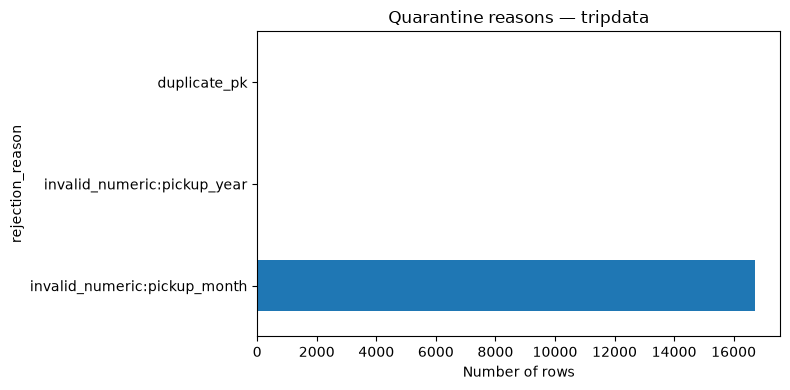

In [42]:
import matplotlib.pyplot as plt

if len(quarantine_df):
    counts = quarantine_df["rejection_reason"].value_counts()
    fig, ax = plt.subplots(figsize=(8, 4))
    counts.plot(kind="barh", ax=ax)
    ax.set_xlabel("Number of rows")
    ax.set_title(f"Quarantine reasons — {DATASET}")
    plt.tight_layout()
    os.makedirs("reports", exist_ok=True)
    plt.savefig(f"reports/quarantine_{DATASET}.png", dpi=150)
    plt.show()
else:
    print("Nothing quarantined for this dataset/run.")

## Data catalog summary & report

In [43]:
catalog_rows = []
for name, cfg in configs.items():
    try:
        s = DeltaTable(cfg.silver_path()).to_pandas()
        q = DeltaTable(cfg.quarantine_path()).to_pandas()
        total = len(s) + len(q)
        catalog_rows.append({
            "dataset": name,
            "primary_key": ", ".join(cfg.primary_key),
            "partition_by": ", ".join(cfg.partition_by) or "(none)",
            "silver_columns": len(s.columns),
            "silver_rows": len(s),
            "quarantined_rows": len(q),
            "quarantine_rate_pct": round(100 * len(q) / total, 2) if total else 0.0,
        })
    except Exception:
        catalog_rows.append({"dataset": name, "primary_key": "", "partition_by": "",
                              "silver_columns": None, "silver_rows": None,
                              "quarantined_rows": None, "quarantine_rate_pct": None})

catalog_df = pd.DataFrame(catalog_rows)
catalog_df

,dataset,primary_key,partition_by,silver_columns,silver_rows,quarantined_rows,quarantine_rate_pct
0,tripdata,trip_id,"pickup_year, pickup_month",31,9538046,16732,0.18
1,weather,event_timestamp,(none),32,8784,0,0.00
2,air_quality,"state_code, county_code, site_num, parameter_c...",measurement_year,33,8131572,7979,0.10
3,taxi_zone_lookup,location_id,(none),9,265,0,0.00


In [44]:
os.makedirs("reports", exist_ok=True)
catalog_df.to_csv("reports/data_catalog_summary.csv", index=False)
summary_df.to_csv("reports/ingestion_run_summary.csv", index=False)
print("Saved reports/data_catalog_summary.csv and reports/ingestion_run_summary.csv")

Saved reports/data_catalog_summary.csv and reports/ingestion_run_summary.csv


In [23]:
spark.stop()

In [46]:
quarantine_df.groupby("rejection_reason").size().reset_index(
    name="count"
).sort_values("count", ascending=False)



,rejection_reason,count
1,invalid_numeric:pickup_month,16721
2,invalid_numeric:pickup_year,9
0,duplicate_pk,2
